<a href="https://colab.research.google.com/github/zijierongjay/MSSP607/blob/main/Modules/Week_13/Participation_Activity_Week_13_Financial_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

zijierongjay

Task 1

In [1]:
!pip install -q yfinance

In [2]:
import yfinance as yf
import pandas as pd

In [3]:
apple = yf.download(
    'AAPL',
    start='2023-01-01',
    end='2024-01-01',
    auto_adjust=False
)

meta = yf.download(
    'META',
    start='2023-01-01',
    end='2024-01-01',
    auto_adjust=False
)

google = yf.download(
    'GOOG',
    start='2023-01-01',
    end='2024-01-01',
    auto_adjust=False
)

netflix = yf.download(
    'NFLX',
    start='2023-01-01',
    end='2024-01-01',
    auto_adjust=False
)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [4]:
apple.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2023-01-03,122.783447,125.070000,130.899994,124.169998,130.279999,112117500
2023-01-04,124.049866,126.360001,128.660004,125.080002,126.889999,89113600
2023-01-05,122.734367,125.019997,127.769997,124.760002,127.129997,80962700
2023-01-06,127.250259,129.619995,130.289993,124.889999,126.010002,87754700
2023-01-09,127.770584,130.149994,133.410004,129.889999,130.470001,70790800


In [5]:
print("Apple:", apple.shape)
print("Meta:", meta.shape)
print("Google:", google.shape)
print("Netflix:", netflix.shape)

Apple: (250, 6)
Meta: (250, 6)
Google: (250, 6)
Netflix: (250, 6)


In [6]:
apple.columns

MultiIndex([('Adj Close', 'AAPL'),
            (    'Close', 'AAPL'),
            (     'High', 'AAPL'),
            (      'Low', 'AAPL'),
            (     'Open', 'AAPL'),
            (   'Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Task 2

In [7]:
apple.columns = apple.columns.get_level_values(0)
meta.columns = meta.columns.get_level_values(0)
google.columns = google.columns.get_level_values(0)
netflix.columns = netflix.columns.get_level_values(0)

In [8]:
apple.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

In [9]:
apple['Ticker'] = 'AAPL'
meta['Ticker'] = 'META'
google['Ticker'] = 'GOOG'
netflix['Ticker'] = 'NFLX'

In [10]:
combined_stocks = pd.concat(
    [apple, meta, google, netflix]
)

combined_stocks.head()

Price,Adj Close,Close,High,Low,Open,Volume,Ticker
Date,,,,,,,
2023-01-03,122.783447,125.070000,130.899994,124.169998,130.279999,112117500,AAPL
2023-01-04,124.049866,126.360001,128.660004,125.080002,126.889999,89113600,AAPL
2023-01-05,122.734367,125.019997,127.769997,124.760002,127.129997,80962700,AAPL
2023-01-06,127.250259,129.619995,130.289993,124.889999,126.010002,87754700,AAPL
2023-01-09,127.770584,130.149994,133.410004,129.889999,130.470001,70790800,AAPL


In [11]:
combined_stocks.shape

(1000, 7)

In [12]:
combined_stocks['Ticker'].value_counts()

,count
Ticker,
AAPL,250
META,250
GOOG,250
NFLX,250


Task 3

In [13]:
tickers = ['AAPL', 'META', 'GOOG', 'NFLX']

metrics = [
    'quickRatio',
    'currentRatio',
    'totalRevenue',
    'debtToEquity',
    'revenuePerShare',
    'returnOnAssets',
    'returnOnEquity',
    'grossProfits'
]

financial_data = []

for ticker in tickers:
    info = yf.Ticker(ticker).info

    row = {'Ticker': ticker}

    for metric in metrics:
        row[metric] = info.get(metric)

    financial_data.append(row)

financial_metrics = pd.DataFrame(financial_data)

financial_metrics


,Ticker,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
0,AAPL,0.827,1.023,478833999872,84.286,32.658,0.25868,1.42257,233602007040
1,META,1.669,1.903,241605001216,42.161,95.186,0.14577,0.32264,195782000640
2,GOOG,2.512,2.786,471097999360,22.187,38.789,0.12743,0.44286,286698012672
3,NFLX,0.836,1.075,49734631424,59.857,11.860,0.17124,0.53463,25207793664


In [14]:
financial_metrics.isnull().sum()

,0
Ticker,0
quickRatio,0
currentRatio,0
totalRevenue,0
debtToEquity,0
revenuePerShare,0
returnOnAssets,0
returnOnEquity,0
grossProfits,0


In [15]:
financial_metrics

,Ticker,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
0,AAPL,0.827,1.023,478833999872,84.286,32.658,0.25868,1.42257,233602007040
1,META,1.669,1.903,241605001216,42.161,95.186,0.14577,0.32264,195782000640
2,GOOG,2.512,2.786,471097999360,22.187,38.789,0.12743,0.44286,286698012672
3,NFLX,0.836,1.075,49734631424,59.857,11.860,0.17124,0.53463,25207793664


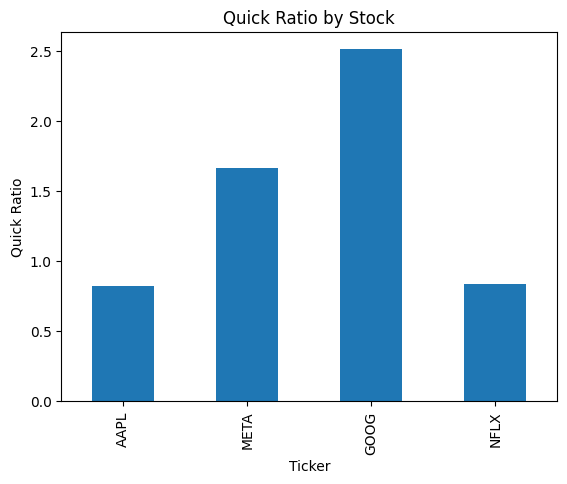

In [16]:
import matplotlib.pyplot as plt

financial_metrics.plot(
    x='Ticker',
    y='quickRatio',
    kind='bar',
    legend=False
)

plt.title('Quick Ratio by Stock')
plt.ylabel('Quick Ratio')
plt.xlabel('Ticker')
plt.show()

In [17]:
financial_metrics

,Ticker,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
0,AAPL,0.827,1.023,478833999872,84.286,32.658,0.25868,1.42257,233602007040
1,META,1.669,1.903,241605001216,42.161,95.186,0.14577,0.32264,195782000640
2,GOOG,2.512,2.786,471097999360,22.187,38.789,0.12743,0.44286,286698012672
3,NFLX,0.836,1.075,49734631424,59.857,11.860,0.17124,0.53463,25207793664


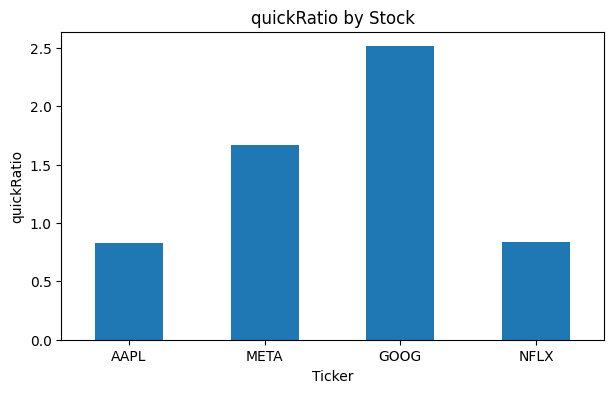

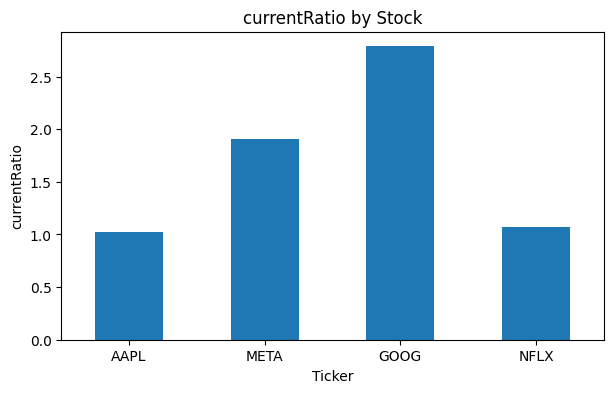

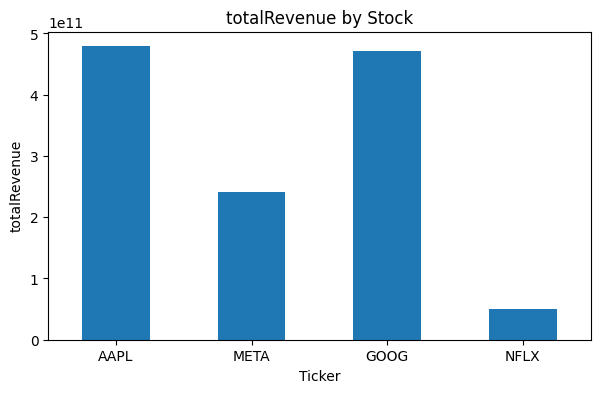

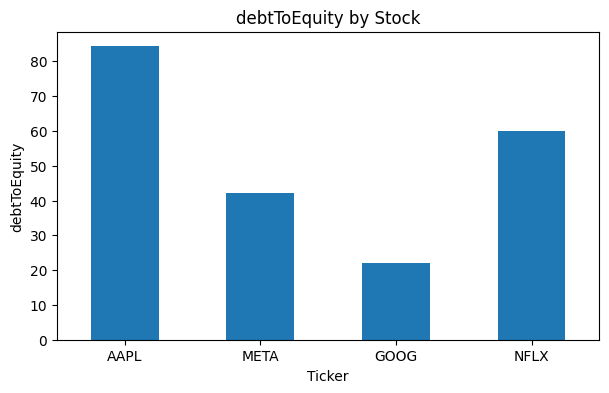

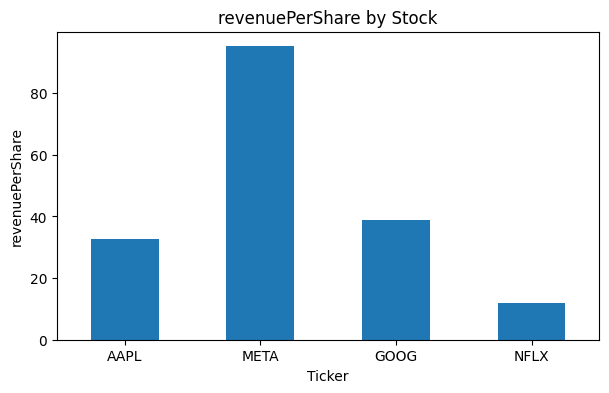

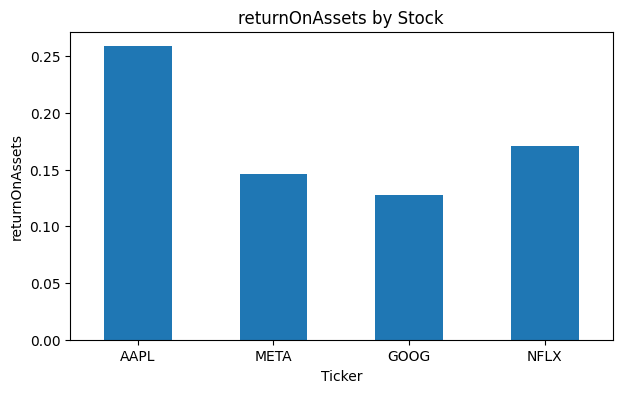

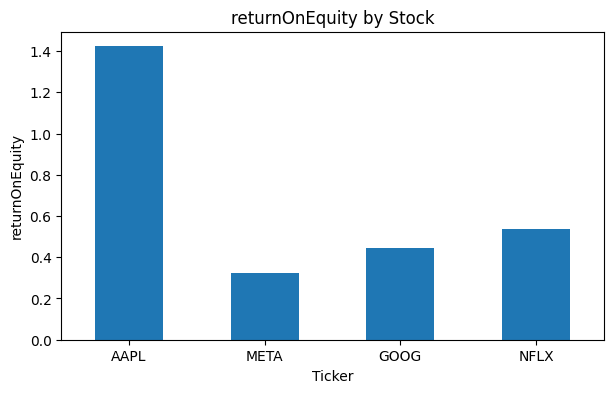

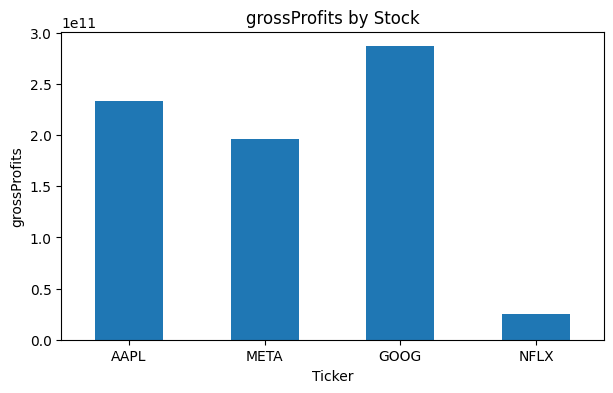

In [18]:
metrics = [
    'quickRatio',
    'currentRatio',
    'totalRevenue',
    'debtToEquity',
    'revenuePerShare',
    'returnOnAssets',
    'returnOnEquity',
    'grossProfits'
]

for metric in metrics:
    financial_metrics.plot(
        x='Ticker',
        y=metric,
        kind='bar',
        legend=False,
        figsize=(7, 4)
    )

    plt.title(f'{metric} by Stock')
    plt.xlabel('Ticker')
    plt.ylabel(metric)
    plt.xticks(rotation=0)
    plt.show()

Task 4

<Figure size 800x600 with 0 Axes>

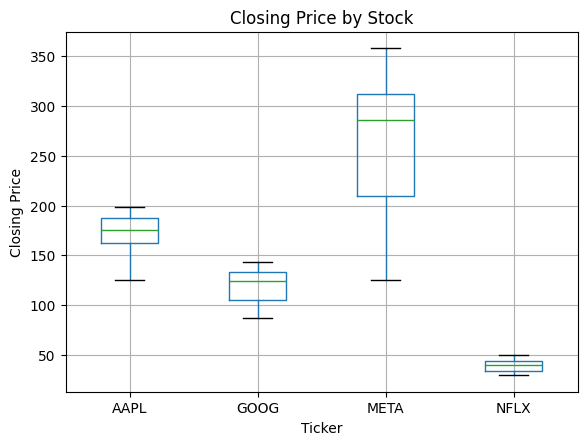

In [19]:
plt.figure(figsize=(8, 6))

combined_stocks.boxplot(
    column='Close',
    by='Ticker'
)

plt.title('Closing Price by Stock')
plt.suptitle('')
plt.xlabel('Ticker')
plt.ylabel('Closing Price')
plt.show()

Task 5

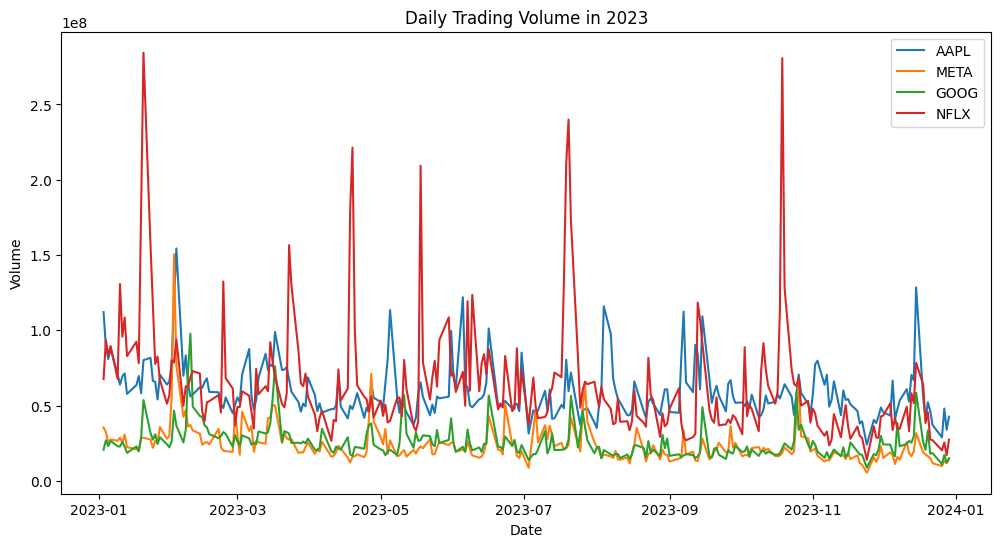

In [20]:
# Task 5: Daily Trading Volume Visualization for 2023

plt.figure(figsize=(12, 6))

for ticker in combined_stocks['Ticker'].unique():
    stock_data = combined_stocks[
        combined_stocks['Ticker'] == ticker
    ]

    plt.plot(
        stock_data.index,
        stock_data['Volume'],
        label=ticker
    )

plt.title('Daily Trading Volume in 2023')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()